# E1 · Limpieza Estadística, Integración y Puerta de Calidad (Bronze → Silver → Gold)

**Proyecto:** Observatorio de exposición digital de pymes de distribución (Colima)  
**Objetivo:** Transformar los archivos crudos de `data/bronze/` (NVD API 2.0 y CISA KEV) en tablas analíticas limpias (`data/silver/` y `data/gold/`) mediante diagnósticos estadísticos formales y validación estricta con **Pandera + Cuarentena**.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Localizar la raíz del repositorio funcione desde docs/E1/ o desde la raíz
RAIZ = Path.cwd().resolve()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parents[1]

sys.path.insert(0, str(RAIZ / "src" / "bronze"))
sys.path.insert(0, str(RAIZ / "src" / "silver"))
sys.path.insert(0, str(RAIZ / "src" / "gold"))

from common import cargar_grupos
import limpieza
import series
import calidad

sns.set_theme(style="whitegrid")
print("Raíz del proyecto:", RAIZ)


Raíz del proyecto: C:\Dev2\observatorio-pymes\observatorio-pymes


## 1. Integración de Fuentes Heterogéneas y Resolución de Conflictos

Contrastamos y unificamos dos fuentes con esquemas incompatibles:
1. **Identificadores:** `cve.id` (NVD) ↔ `cveID` (KEV).
2. **Fechas:** ISO-8601 con hora (`published`, `lastModified`) ↔ fecha simple `YYYY-MM-DD` (`dateAdded`, `dueDate`).
3. **Métricas CVSS anidadas:** Resolución jerárquica `CVSS v3.1 → CVSS v3.0 → CVSS v2.0`.
4. **Duplicados por palabras clave:** Eliminación de registros repetidos por `(grupo, cve_id)` conservando la versión más reciente.


In [2]:
cfg = cargar_grupos()
grupos = cfg["grupos"]

nvd_crudo = limpieza.extraer_nvd_crudo(RAIZ / "data" / "bronze" / "nvd", grupos)
kev_crudo = limpieza.extraer_kev_crudo(RAIZ / "data" / "bronze" / "kev", grupos)

nvd_parsed, _ = limpieza._parsear_nvd_con_cuarentena(nvd_crudo)
nvd_dedup = nvd_parsed.sort_values("last_modified", ascending=False).drop_duplicates(
    subset=["grupo", "cve_id"], keep="first"
).copy()

print(f"Registros NVD crudos:        {len(nvd_crudo)}")
print(f"Duplicados por keyword:      {len(nvd_parsed) - len(nvd_dedup)}")
print(f"CVEs únicos (grupo, cve_id): {len(nvd_dedup)}")
print(f"Registros en CISA KEV:       {len(kev_crudo)}")


Registros NVD crudos:        1844
Duplicados por keyword:      42
CVEs únicos (grupo, cve_id): 1802
Registros en CISA KEV:       1773


## 2. Diagnóstico de Valores Faltantes (MCAR / MAR / MNAR) e Imputación

Analizamos si la ausencia de puntuación `cvss_base` es completamente aleatoria (**MCAR**) o depende de variables observadas como el estado de análisis del CVE en NVD (`vuln_status`: `Deferred`, `Awaiting Analysis`, `Analyzed`, `Modified`) (**MAR**).


Resumen diagnóstico:
  total_registros: 1802
  faltantes_cvss: 69
  porcentaje_faltantes_cvss: 3.83
  faltantes_attack_vector: 69
  faltantes_cwe: 5
  mecanismo_diagnosticado: MAR (dependiente de vuln_status)
  chi2_stat: 469.5604
  chi2_pvalue: 2.5630422973387244e-100
  detalle_por_status: {'Deferred': 55, 'Awaiting Analysis': 13, 'Received': 1}


,CVSS Presente,CVSS Faltante
vuln_status,,
Analyzed,1076,0
Awaiting Analysis,34,13
Deferred,136,55
Modified,486,0
Received,1,1


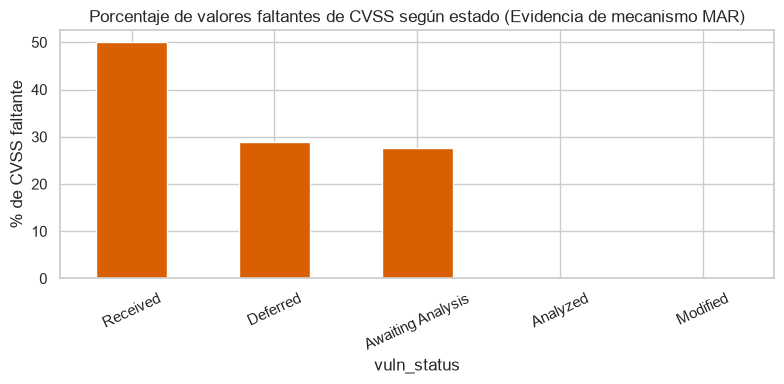

In [3]:
diag = limpieza.diagnosticar_faltantes(nvd_dedup)
print("Resumen diagnóstico:")
for k, v in diag.items():
    print(f"  {k}: {v}")

tabla_contingencia = pd.crosstab(nvd_dedup["vuln_status"], nvd_dedup["cvss_base"].isna())
tabla_contingencia.columns = ["CVSS Presente", "CVSS Faltante"]
display(tabla_contingencia)

fig, ax = plt.subplots(figsize=(8, 4))
pct_faltante = (nvd_dedup["cvss_base"].isna().groupby(nvd_dedup["vuln_status"]).mean() * 100).sort_values(ascending=False)
pct_faltante.plot(kind="bar", color="#d95f02", ax=ax)
ax.set_ylabel("% de CVSS faltante")
ax.set_title("Porcentaje de valores faltantes de CVSS según estado (Evidencia de mecanismo MAR)")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()


**Conclusión estadística:** Con $\chi^2 = 469.56$ y $p pprox 2.56 	imes 10^{-100} \ll 0.05$, se rechaza la hipótesis de independencia (MCAR). La ausencia de CVSS sigue un mecanismo **MAR (Missing At Random)** gobernado por el estado de revisión (`Deferred` y `Awaiting Analysis`).

**Estrategia de imputación:** Imputación por **mediana jerárquica de grupo tecnológico** (robusta frente a sesgos de severidad) manteniendo la columna de auditoría `cvss_imputado = True`.


## 3. Puerta de Calidad Automática (Pandera) y Cuarentena

Validamos todos los registros con esquemas estrictos de **Pandera (`lazy=True`)** antes de promoverlos a `data/silver/vulnerabilidades.csv`. Además, demostramos con casos sucios sintéticos que ningún registro inválido pasa ni se borra en silencio: todos se desvían con su `motivo_cuarentena`.


In [4]:
resumen_silver = limpieza.ejecutar_pipeline_silver()
print("Resultado Silver real:", {k: v for k, v in resumen_silver.items() if k != "diagnostico_faltantes"})

# Demostración controlada de la Puerta de Calidad con registros inválidos inyectados
df_silver_real = pd.read_csv(RAIZ / "data" / "silver" / "vulnerabilidades.csv")
df_prueba_sucia = pd.DataFrame([
    {"cve_id": "CVE-2025-99999", "grupo": "camaras_ip", "vuln_status": "Analyzed",
     "published": "2025-01-10", "last_modified": "2025-01-12", "cvss_base": 8.5,
     "num_refs": 2, "descripcion": "Registro valido de control", "en_kev": False,
     "kev_date_added": pd.NaT, "dias_a_kev": np.nan},
    {"cve_id": "ID-INVALIDO", "grupo": "camaras_ip", "vuln_status": "Rejected",
     "published": "2025-01-10", "last_modified": "2025-01-01", "cvss_base": 15.5,
     "num_refs": -1, "descripcion": "ok", "en_kev": False,
     "kev_date_added": pd.NaT, "dias_a_kev": np.nan},
])
df_prueba_sucia["published"] = pd.to_datetime(df_prueba_sucia["published"])
df_prueba_sucia["last_modified"] = pd.to_datetime(df_prueba_sucia["last_modified"])

validos_demo, cuarentena_demo = calidad.validar_con_cuarentena(
    df_prueba_sucia, calidad.esquema_pre_limpieza(list(grupos.keys())), etapa="demo_notebook"
)
print(f"Válidos: {len(validos_demo)} | Enviados a cuarentena: {len(cuarentena_demo)}")
display(cuarentena_demo[["cve_id", "vuln_status", "cvss_base", "motivo_cuarentena"]])


Resultado Silver real: {'ingestado_utc': '2026-11-12T15:34:38.745843+00:00', 'registros_nvd_crudos': 1844, 'duplicados_keyword_eliminados': 42, 'registros_silver_validos': 1802, 'registros_cuarentena': 0, 'coincidencias_nvd_kev': 18, 'sha256_silver': '000838a0a50a176277fe1745ba84a259f770675b2ad4c09d02c751dd2f902380'}
Válidos: 1 | Enviados a cuarentena: 1


,cve_id,vuln_status,cvss_base,motivo_cuarentena
1,ID-INVALIDO,Rejected,15.5,cve_id: fechas_coherentes_nvd (valor=ID-INVALI...


## 4. Detección de Atípicos, Normalización, Discretización y Reducción (Capa Gold)

Ejecutamos la transformación hacia `data/gold/series_mensuales.csv`:
- **Agregación mensual** (61 periodos contiguos por cada grupo = 366 filas).
- **Atípicos:** Detección mediante **IQR (Tukey)** y **Z-Score Robusto (MAD)**, generando `total_cves_tratado` (winsorizado) sin alterar `total_cves` original.
- **Normalización y estandarización:** `Min-Max` $[0, 1]$ y `Z-Score` por grupo.
- **Discretización y jerarquías:** `nivel_riesgo_mensual`, `macro_categoria`, `anio`, `trimestre`.
- **Reducción:** Selección de 13 variables no redundantes en `data/gold/series_modelo.csv`.


Resumen Gold: {'ingestado_utc': '2026-11-12T15:34:39.625133+00:00', 'filas_gold': 366, 'periodos_por_grupo': 61, 'atipicos_iqr_detectados': 22, 'atipicos_mad_detectados': 13, 'columnas_completas': 24, 'columnas_reducidas': 13, 'sha256_gold': 'd89d45a620e5a7b868c23aab030f797050064cbde7d060cc9baab3cbee447dfc', 'sha256_modelo': '465ff1c4f797afcb9617730d5efddc7d568db3f6b354ac17c320c828693ac6c7'}

Atípicos detectados por grupo:


,total_cves,total_cves_tratado,es_atipico_iqr,es_atipico_mad
grupo,,,,
camaras_ip,25,17.0,2,5
contpaqi,1,1.0,0,0
impresoras_hp,9,2.5,5,0
modems_red,9,5.0,4,3
soporte_remoto,14,2.5,6,0
windows_office,218,45.0,5,5


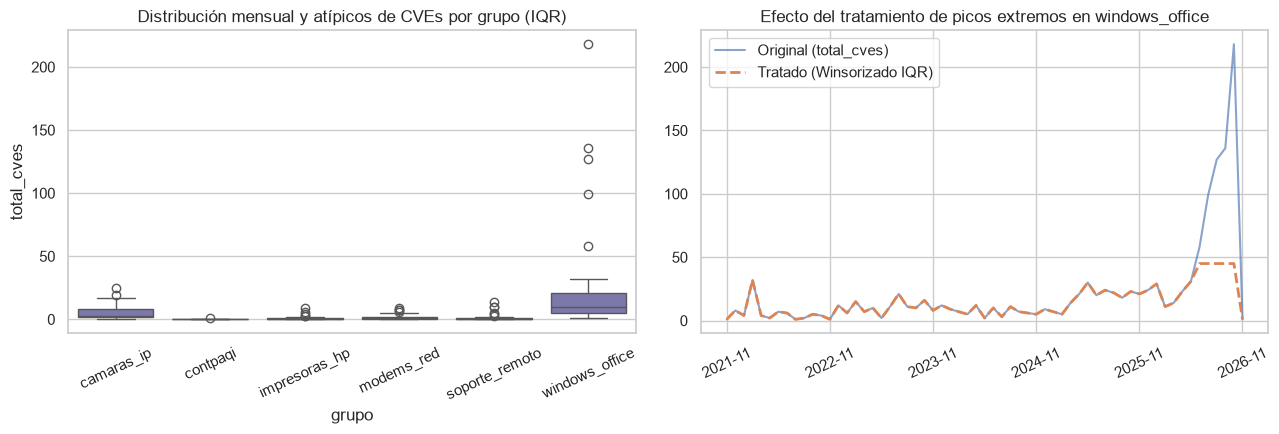

In [5]:
resumen_gold = series.ejecutar_pipeline_gold()
print("Resumen Gold:", resumen_gold)

df_gold = pd.read_csv(RAIZ / "data" / "gold" / "series_mensuales.csv")
df_modelo = pd.read_csv(RAIZ / "data" / "gold" / "series_modelo.csv")

print("\nAtípicos detectados por grupo:")
display(df_gold.groupby("grupo")[["total_cves", "total_cves_tratado"]].max().join(
    df_gold.groupby("grupo")[["es_atipico_iqr", "es_atipico_mad"]].sum()
))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df_gold, x="grupo", y="total_cves", ax=axes[0], color="#7570b3")
axes[0].set_title("Distribución mensual y atípicos de CVEs por grupo (IQR)")
axes[0].tick_params(axis="x", rotation=25)

win = df_gold[df_gold["grupo"] == "windows_office"]
axes[1].plot(win["periodo"], win["total_cves"], label="Original (total_cves)", alpha=0.65)
axes[1].plot(win["periodo"], win["total_cves_tratado"], label="Tratado (Winsorizado IQR)", linestyle="--", linewidth=2)
axes[1].set_title("Efecto del tratamiento de picos extremos en windows_office")
axes[1].set_xticks(win["periodo"].iloc[::12])
axes[1].tick_params(axis="x", rotation=25)
axes[1].legend()

plt.tight_layout()
plt.show()


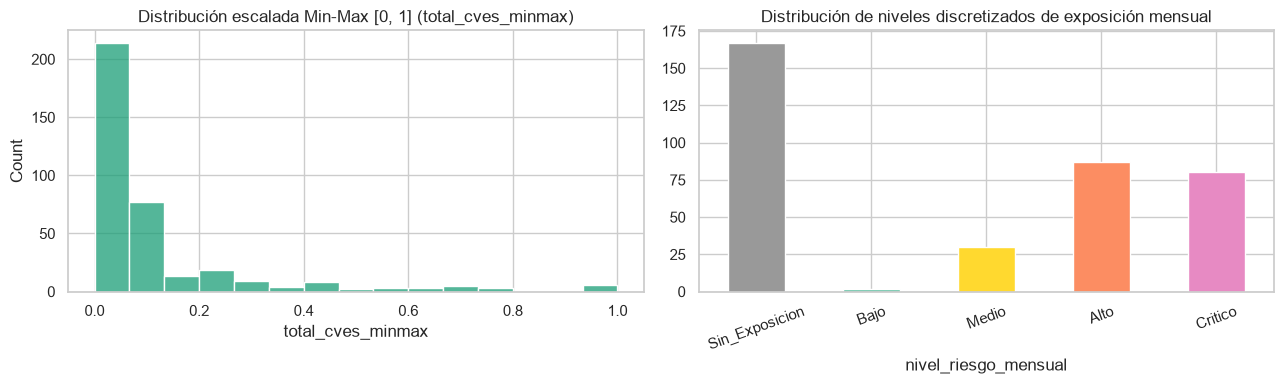

Dimensiones Gold completo: (366, 24) | Gold reducido (modelo): (366, 13)


,grupo,macro_categoria,periodo,anio,trimestre,total_cves,total_cves_tratado,total_cves_minmax,total_cves_zscore,cvss_promedio,conteo_kev_catalogo,conteo_ransomware,nivel_riesgo_mensual
0,camaras_ip,Infraestructura_Red,2021-11,2021,Q4,5,5.0,0.20,-0.037008,7.10,1,0,Critico
1,camaras_ip,Infraestructura_Red,2021-12,2021,Q4,1,1.0,0.04,-0.789499,6.10,0,0,Medio
2,camaras_ip,Infraestructura_Red,2022-01,2022,Q1,2,2.0,0.08,-0.601377,7.55,0,0,Critico
3,camaras_ip,Infraestructura_Red,2022-02,2022,Q1,0,0.0,0.00,-0.977622,0.00,0,0,Sin_Exposicion
4,camaras_ip,Infraestructura_Red,2022-03,2022,Q1,4,4.0,0.16,-0.225131,6.60,0,0,Critico


In [6]:
# Verificación visual de Normalización Min-Max vs Z-Score y Discretización
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_gold["total_cves_minmax"], bins=15, kde=False, ax=axes[0], color="#1b9e77")
axes[0].set_title("Distribución escalada Min-Max [0, 1] (total_cves_minmax)")

orden_riesgo = ["Sin_Exposicion", "Bajo", "Medio", "Alto", "Critico"]
df_gold["nivel_riesgo_mensual"].value_counts().reindex(orden_riesgo).fillna(0).plot(
    kind="bar", ax=axes[1], color=["#999999", "#66c2a5", "#ffd92f", "#fc8d62", "#e78ac3"]
)
axes[1].set_title("Distribución de niveles discretizados de exposición mensual")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print("Dimensiones Gold completo:", df_gold.shape, "| Gold reducido (modelo):", df_modelo.shape)
display(df_modelo.head(5))
